Q1

Linear Spatial-Domain Filtering (Smoothing)

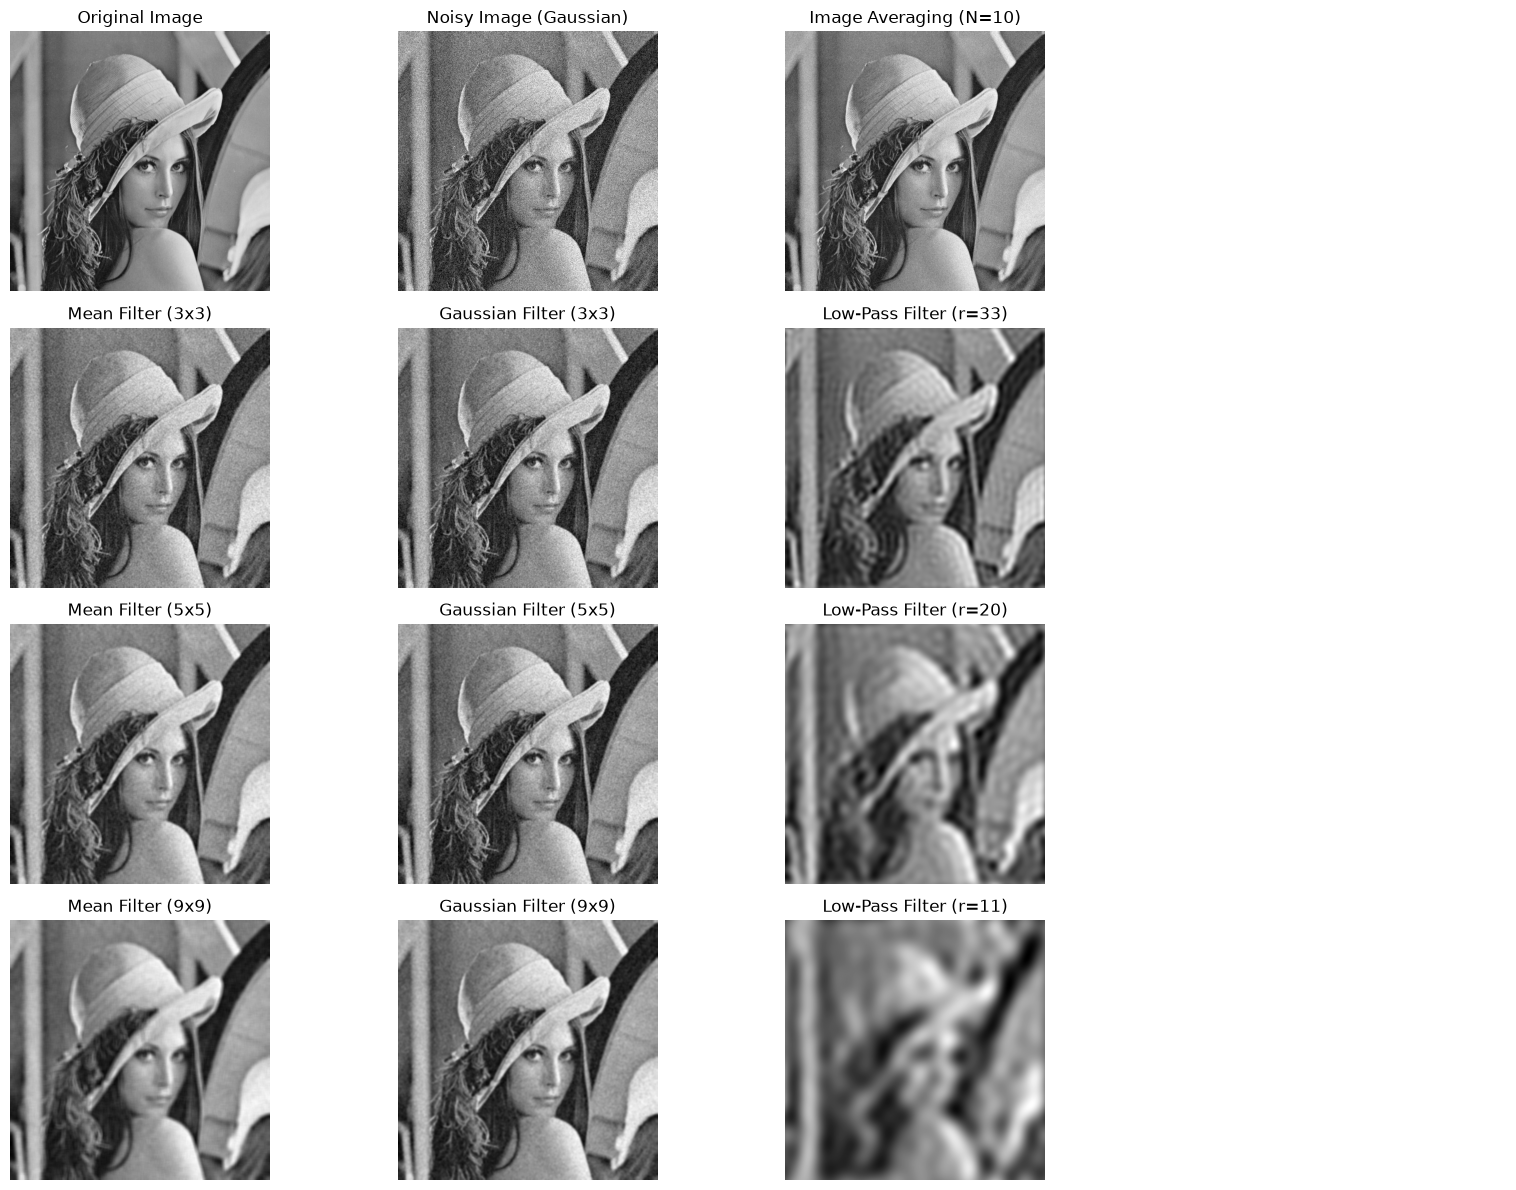

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load or generate test image
img = cv2.imread("lenna.png", cv2.IMREAD_GRAYSCALE)
if img is None:
    img = np.zeros((256, 256), dtype=np.uint8)
    cv2.circle(img, (128, 128), 60, 255, -1)
    cv2.rectangle(img, (40, 40), (90, 90), 180, -1)

# Add Gaussian Noise
noise = np.random.normal(0, 25, img.shape).astype(np.float32)
noisy_img = np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

# --------------------------------------------------
# a. Image Averaging (Simulated over N noisy frames)
# --------------------------------------------------
num_frames = 10
frames = [
    np.clip(
        img.astype(np.float32)
        + np.random.normal(0, 25, img.shape).astype(np.float32),
        0,
        255,
    )
    for _ in range(num_frames)
]
avg_img = np.mean(frames, axis=0).astype(np.uint8)

# --------------------------------------------------
# Experimenting with Kernel Sizes (3x3, 5x5, 9x9)
# --------------------------------------------------
kernel_sizes = [3, 5, 9]

fig, axes = plt.subplots(4, 4, figsize=(16, 12))

# Row 0: Original, Noisy, and Averaged Images
axes[0, 0].imshow(img, cmap="gray")
axes[0, 0].set_title("Original Image")
axes[0, 0].axis("off")

axes[0, 1].imshow(noisy_img, cmap="gray")
axes[0, 1].set_title("Noisy Image (Gaussian)")
axes[0, 1].axis("off")

axes[0, 2].imshow(avg_img, cmap="gray")
axes[0, 2].set_title(f"Image Averaging (N={num_frames})")
axes[0, 2].axis("off")

axes[0, 3].axis("off")  # empty slot

# Rows 1 to 3: Kernel Comparisons (Mean, Gaussian, Ideal Low-Pass)
for idx, k in enumerate(kernel_sizes, start=1):
    # b. Mean Filter (Box Filter)
    mean_filtered = cv2.blur(noisy_img, (k, k))

    # c. Gaussian Filter
    gaussian_filtered = cv2.GaussianBlur(noisy_img, (k, k), 0)

    # d. Low-Pass Filter (Ideal LPF via DFT)
    dft = np.fft.fft2(noisy_img)
    dft_shift = np.fft.fftshift(dft)
    rows, cols = noisy_img.shape
    crow, ccol = rows // 2, cols // 2

    # Create LPF mask where cutoff radius corresponds to kernel size
    radius = max(10, 100 // k)
    mask = np.zeros((rows, cols), np.uint8)
    cv2.circle(mask, (ccol, crow), radius, 1, -1)

    fshift = dft_shift * mask
    f_ishift = np.fft.ifftshift(fshift)
    lpf_filtered = np.abs(np.fft.ifft2(f_ishift))
    lpf_filtered = np.clip(lpf_filtered, 0, 255).astype(np.uint8)

    # Plot
    axes[idx, 0].imshow(mean_filtered, cmap="gray")
    axes[idx, 0].set_title(f"Mean Filter ({k}x{k})")
    axes[idx, 0].axis("off")

    axes[idx, 1].imshow(gaussian_filtered, cmap="gray")
    axes[idx, 1].set_title(f"Gaussian Filter ({k}x{k})")
    axes[idx, 1].axis("off")

    axes[idx, 2].imshow(lpf_filtered, cmap="gray")
    axes[idx, 2].set_title(f"Low-Pass Filter (r={radius})")
    axes[idx, 2].axis("off")

    axes[idx, 3].axis("off")

plt.tight_layout()
plt.show()

Q2

Non-Linear Spatial Filtering

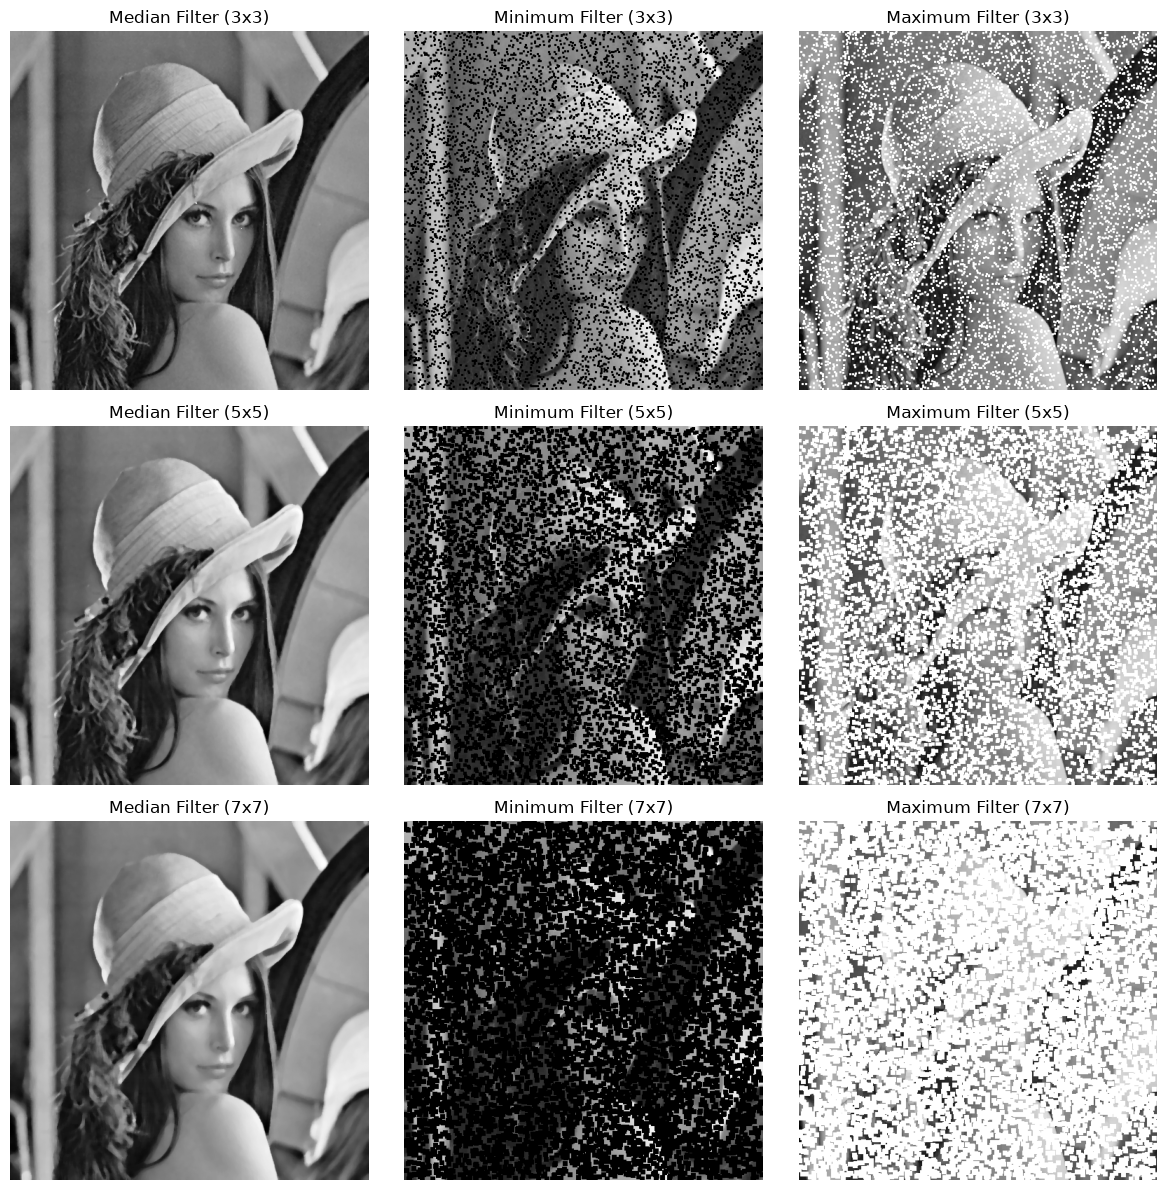

In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import maximum_filter, minimum_filter


def add_salt_and_pepper_noise(image, salt_prob=0.02, pepper_prob=0.02):
    noisy = np.copy(image)
    # Salt noise (white pixels)
    num_salt = np.ceil(salt_prob * image.size)
    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
    noisy[tuple(coords)] = 255

    # Pepper noise (black pixels)
    num_pepper = np.ceil(pepper_prob * image.size)
    coords = [
        np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape
    ]
    noisy[tuple(coords)] = 0
    return noisy


# Load base image
img = cv2.imread("lenna.png", cv2.IMREAD_GRAYSCALE)
if img is None:
    img = np.zeros((256, 256), dtype=np.uint8)
    cv2.circle(img, (128, 128), 60, 255, -1)

# Add Salt-and-Pepper Noise
sp_noisy = add_salt_and_pepper_noise(img, salt_prob=0.03, pepper_prob=0.03)

kernel_sizes = [3, 5, 7]
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, k in enumerate(kernel_sizes):
    # a. Median Filter
    median_filtered = cv2.medianBlur(sp_noisy, k)

    # b. Minimum Filter
    min_filtered = minimum_filter(sp_noisy, size=k)

    # c. Maximum Filter
    max_filtered = maximum_filter(sp_noisy, size=k)

    axes[row, 0].imshow(median_filtered, cmap="gray")
    axes[row, 0].set_title(f"Median Filter ({k}x{k})")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(min_filtered, cmap="gray")
    axes[row, 1].set_title(f"Minimum Filter ({k}x{k})")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(max_filtered, cmap="gray")
    axes[row, 2].set_title(f"Maximum Filter ({k}x{k})")
    axes[row, 2].axis("off")

plt.tight_layout()
plt.show()

Max Pixel Difference: 0
Mean Pixel Difference: 0.0000


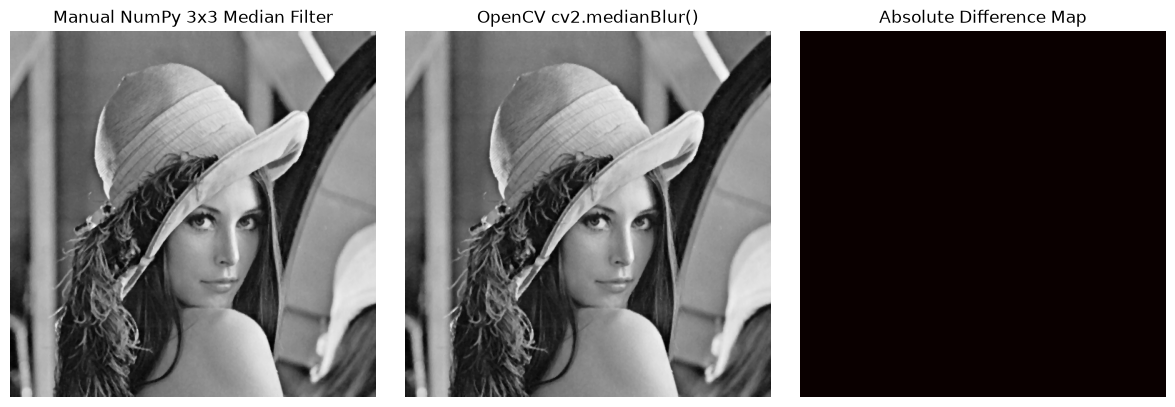

In [4]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


def manual_median_filter_3x3(image):
    pad_img = np.pad(image, pad_width=1, mode="edge")
    h, w = image.shape
    output = np.zeros_like(image)

    # Extract 3x3 sliding window neighborhoods without nested loops
    neighborhoods = np.array([
        pad_img[0:h, 0:w],
        pad_img[0:h, 1 : w + 1],
        pad_img[0:h, 2 : w + 2],
        pad_img[1 : h + 1, 0:w],
        pad_img[1 : h + 1, 1 : w + 1],
        pad_img[1 : h + 1, 2 : w + 2],
        pad_img[2 : h + 2, 0:w],
        pad_img[2 : h + 2, 1 : w + 1],
        pad_img[2 : h + 2, 2 : w + 2],
    ])

    # Compute median along neighborhood axis
    output = np.median(neighborhoods, axis=0).astype(np.uint8)
    return output


# Generate test image with salt & pepper noise
test_img = cv2.imread("lenna.png", cv2.IMREAD_GRAYSCALE)
if test_img is None:
    test_img = np.random.randint(0, 255, (256, 256), dtype=np.uint8)

noisy = add_salt_and_pepper_noise(test_img)

# Compute filtered results
manual_res = manual_median_filter_3x3(noisy)
opencv_res = cv2.medianBlur(noisy, 3)

# Calculate difference matrix
diff = np.abs(manual_res.astype(int) - opencv_res.astype(int))

print(f"Max Pixel Difference: {np.max(diff)}")
print(f"Mean Pixel Difference: {np.mean(diff):.4f}")

# Visual Comparison
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(manual_res, cmap="gray")
axes[0].set_title("Manual NumPy 3x3 Median Filter")
axes[0].axis("off")

axes[1].imshow(opencv_res, cmap="gray")
axes[1].set_title("OpenCV cv2.medianBlur()")
axes[1].axis("off")

axes[2].imshow(diff, cmap="hot")
axes[2].set_title("Absolute Difference Map")
axes[2].axis("off")

plt.tight_layout()
plt.show()